<a href="https://colab.research.google.com/github/vaishnaviii7557/pet-classifier/blob/master/notebooks/02_model_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/dataset.zip

Mounted at /content/drive


In [ ]:
import tensorflow as tf

def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"dataset/{split}", image_size=(224, 224),
        batch_size=32, label_mode="binary",
        shuffle=shuffle, seed=42)

train_ds = load("train", True)
val_ds = load("val", False)
test_ds = load("test", False)
print(train_ds.class_names)

Found 3319 files belonging to 2 classes.
Found 711 files belonging to 2 classes.
Found 712 files belonging to 2 classes.
['cat', 'dog']


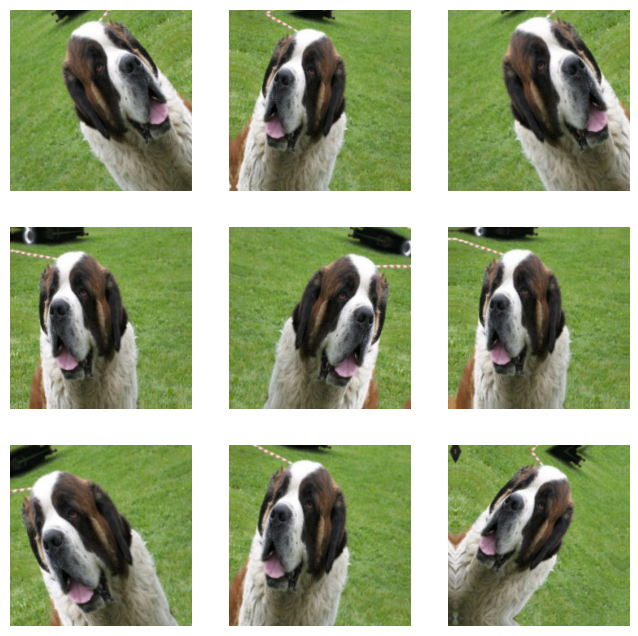

In [ ]:
import matplotlib.pyplot as plt

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

for images, labels in train_ds.take(1):
    img = images[0]
    plt.figure(figsize=(8, 8))
    for i in range(9):
        out = augment(tf.expand_dims(img, 0), training=True)[0]
        plt.subplot(3, 3, i + 1)
        plt.imshow(out.numpy().astype("uint8"))
        plt.axis("off")
    plt.show()

In [ ]:
!ls -lh /content/drive/MyDrive/dataset.zip

-rw------- 1 root root 139M Oct 25 08:50 /content/drive/MyDrive/dataset.zip


In [ ]:
from tensorflow.keras import layers, models

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    augment,
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,649 (92.38 KB)

 Trainable params: 23,649 (92.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")],
)

history = model.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.5056 - loss: 0.6933 - precision: 0.5046 - recall: 0.6211 - val_accuracy: 0.5401 - val_loss: 0.6879 - val_precision: 0.8182 - val_recall: 0.1014
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.5610 - loss: 0.6831 - precision: 0.5666 - recall: 0.5205 - val_accuracy: 0.5401 - val_loss: 0.6747 - val_precision: 0.5224 - val_recall: 0.9183
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.5682 - loss: 0.6755 - precision: 0.5815 - recall: 0.4880 - val_accuracy: 0.5471 - val_loss: 0.6642 - val_precision: 0.5270 - val_recall: 0.9070
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.5803 - loss: 0.6703 - precision: 0.5956 - recall: 0.5012 - val_accuracy: 0.5795 - val_loss: 0.6587 - val_precision: 0.5553 - val_recall: 0.7915
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.5878 - loss: 0.6641 - precision: 0.6028 - recall: 0.5157 - val_accuracy: 0.5513 - val_lo

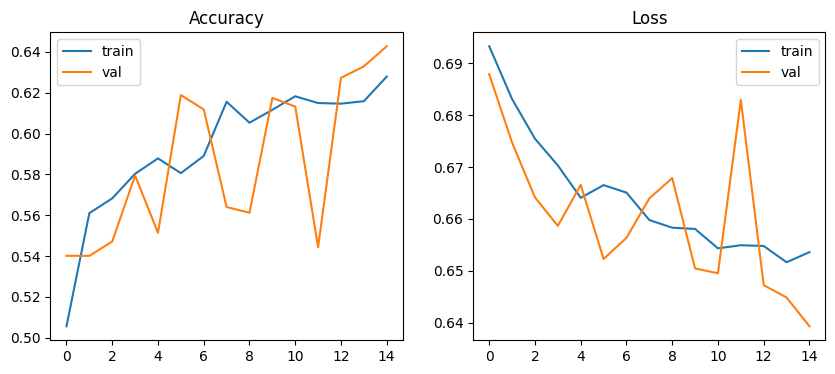

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.legend()
plt.show()

In [ ]:
model.save("baseline_cnn.keras")
!cp baseline_cnn.keras /content/drive/MyDrive/


In [ ]:
def build_cnn():
    m = models.Sequential([
        layers.Input(shape=(224, 224, 3)),
        augment,
        layers.Rescaling(1./255),
    ])
    for f in [32, 64, 128, 128]:
        m.add(layers.Conv2D(f, 3, padding="same", activation="relu"))
        m.add(layers.BatchNormalization())
        m.add(layers.MaxPooling2D())
    m.add(layers.GlobalAveragePooling2D())
    m.add(layers.Dropout(0.3))
    m.add(layers.Dense(1, activation="sigmoid"))
    return m

model2 = build_cnn()
model2.summary()

model2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")],
)

stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True)

history2 = model2.fit(train_ds, validation_data=val_ds,
                      epochs=40, callbacks=[stop])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,369 (946.75 KB)

 Trainable params: 241,665 (944.00 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 137ms/step - accuracy: 0.5785 - loss: 0.7136 - precision: 0.5809 - recall: 0.5645 - val_accuracy: 0.5007 - val_loss: 0.7653 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 14s 131ms/step - accuracy: 0.6119 - loss: 0.6668 - precision: 0.6143 - recall: 0.6024 - val_accuracy: 0.5007 - val_loss: 0.7816 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 14s 130ms/step - accuracy: 0.6225 - loss: 0.6544 - precision: 0.6240 - recall: 0.6169 - val_accuracy: 0.5035 - val_loss: 0.8583 - val_precision: 0.7500 - val_recall: 0.0085
Epoch 4/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 14s 130ms/step - accuracy: 0.6225 - loss: 0.6474 - precision: 0.6249 - recall: 0.6133 - val_accuracy: 0.5935 - val_loss: 0.6620 - val_precision: 0.7357 - val_recall: 0.2901
Epoch 5/40
104/104 ━━━━━━━━━━━━━━━━━━━━ 14s 130ms/step - accuracy: 0.6466 - loss: 0.6405 - precision: 0.6546 - recall: 0.6211 - val_

In [ ]:
model2.save("baseline_cnn_v2.keras")
!cp baseline_cnn_v2.keras /content/drive/MyDrive/

In [ ]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model3 = tf.keras.Model(inputs, outputs)
model3.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_34"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model3.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")],
)

stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True)

history3 = model3.fit(train_ds, validation_data=val_ds,
                      epochs=15, callbacks=[stop])

model3.save("mobilenetv2_frozen.keras")
!cp mobilenetv2_frozen.keras /content/drive/MyDrive/

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 14s 89ms/step - accuracy: 0.9102 - loss: 0.2304 - precision: 0.9321 - recall: 0.8849 - val_accuracy: 0.9803 - val_loss: 0.0976 - val_precision: 0.9803 - val_recall: 0.9803
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step - accuracy: 0.9735 - loss: 0.0894 - precision: 0.9684 - recall: 0.9789 - val_accuracy: 0.9831 - val_loss: 0.0683 - val_precision: 0.9777 - val_recall: 0.9887
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 74ms/step - accuracy: 0.9795 - loss: 0.0729 - precision: 0.9710 - recall: 0.9886 - val_accuracy: 0.9859 - val_loss: 0.0555 - val_precision: 0.9832 - val_recall: 0.9887
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.9828 - loss: 0.0559 - precision: 0.9785 - recall: 0.9873 - val_accuracy: 0.9831 - val_loss: 0.0532 - val_precision: 0.9751 - val_recall: 0.9915
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.9813 - loss: 0.0529 - precision: 0.9762 - recall: 0.9867 - val_accuracy: 0.9831 - val_l

In [ ]:
model4 = tf.keras.models.load_model("mobilenetv2_frozen.keras")
base4 = model4.get_layer("mobilenetv2_1.00_224")

base4.trainable = True
for layer in base4.layers[:-30]:
    layer.trainable = False

model4.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")],
)

stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history4 = model4.fit(train_ds, validation_data=val_ds,
                      epochs=10, callbacks=[stop])

model4.save("mobilenetv2_finetuned.keras")
!cp mobilenetv2_finetuned.keras /content/drive/MyDrive/

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 20s 112ms/step - accuracy: 0.9072 - loss: 0.2404 - precision: 0.8463 - recall: 0.9952 - val_accuracy: 0.9648 - val_loss: 0.0949 - val_precision: 0.9365 - val_recall: 0.9972
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.9641 - loss: 0.0930 - precision: 0.9540 - recall: 0.9753 - val_accuracy: 0.9606 - val_loss: 0.1274 - val_precision: 0.9291 - val_recall: 0.9972
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - accuracy: 0.9732 - loss: 0.0688 - precision: 0.9712 - recall: 0.9753 - val_accuracy: 0.9677 - val_loss: 0.1008 - val_precision: 0.9415 - val_recall: 0.9972
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.9762 - loss: 0.0632 - precision: 0.9782 - recall: 0.9741 - val_accuracy: 0.9719 - val_loss: 0.0850 - val_precision: 0.9491 - val_recall: 0.9972
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.9789 - loss: 0.0606 - precision: 0.9795 - recall: 0.9783 - val_accuracy: 0.9761 - val_

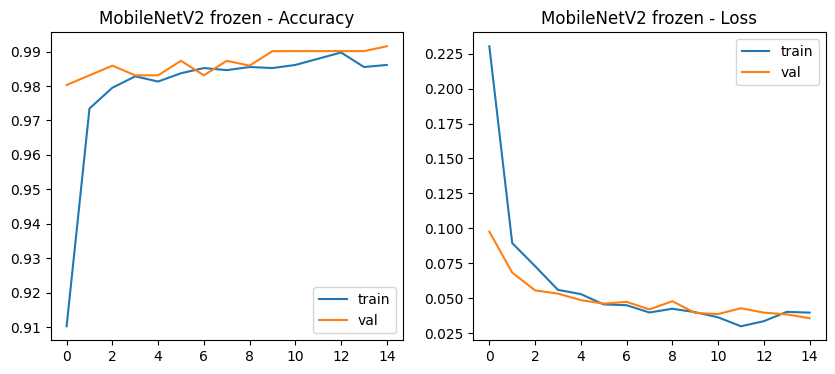

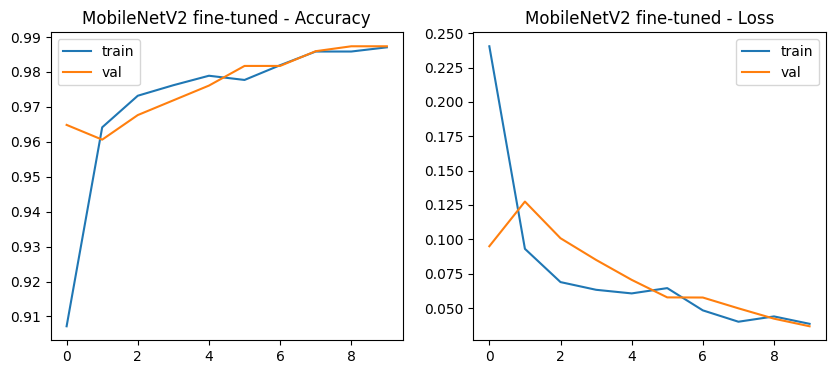

In [ ]:
def plot_history(h, title):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(h.history["accuracy"], label="train")
    plt.plot(h.history["val_accuracy"], label="val")
    plt.title(title + " - Accuracy"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(h.history["loss"], label="train")
    plt.plot(h.history["val_loss"], label="val")
    plt.title(title + " - Loss"); plt.legend()
    plt.show()

plot_history(history3, "MobileNetV2 frozen")
plot_history(history4, "MobileNetV2 fine-tuned")

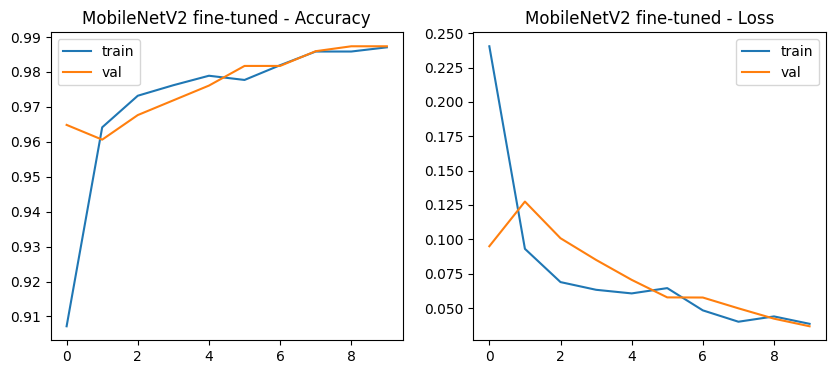

In [ ]:
plot_history(history4, "MobileNetV2 fine-tuned")

In [ ]:
model4.summary()


Model: "functional_34"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,314,629 (20.27 MB)

 Trainable params: 1,527,681 (5.83 MB)

 Non-trainable params: 731,584 (2.79 MB)

 Optimizer params: 3,055,364 (11.66 MB)

In [ ]:
!pip -q install imagehash
import os
from PIL import Image
import imagehash

def get_hashes(split):
    items = []
    for c in ["cat", "dog"]:
        for fn in os.listdir(f"dataset/{split}/{c}"):
            p = f"dataset/{split}/{c}/{fn}"
            items.append((p, imagehash.phash(Image.open(p))))
    return items

H = {s: get_hashes(s) for s in ["train", "val", "test"]}

def find_close(a, b, max_dist=6):
    return [(pa, pb, ha - hb) for pa, ha in a for pb, hb in b
            if ha - hb <= max_dist]

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    pairs = find_close(H[a], H[b])
    print(a, "vs", b, "->", len(pairs), "close pairs")

train vs val -> 4 close pairs
train vs test -> 8 close pairs
val vs test -> 0 close pairs


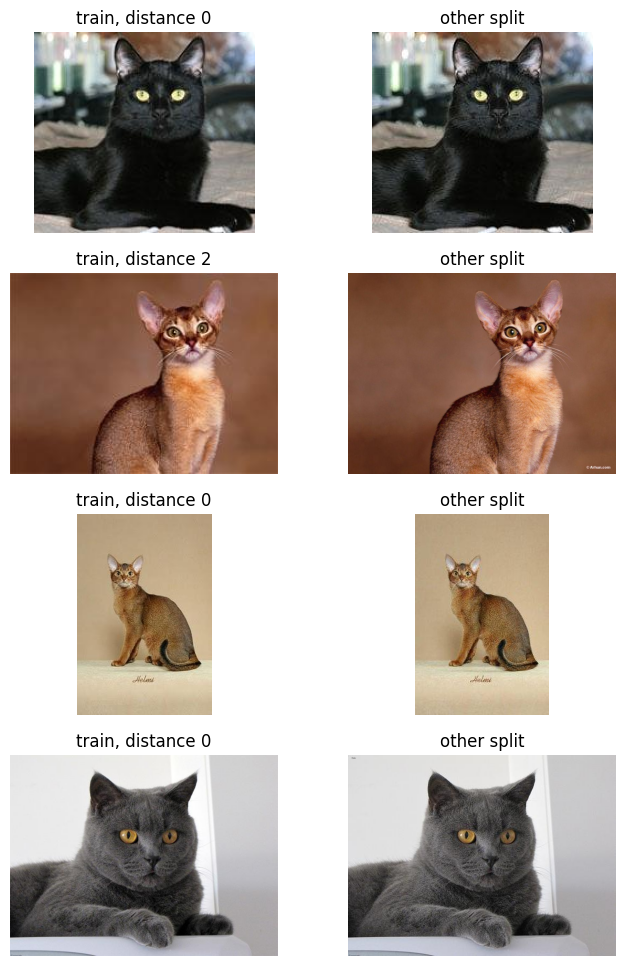

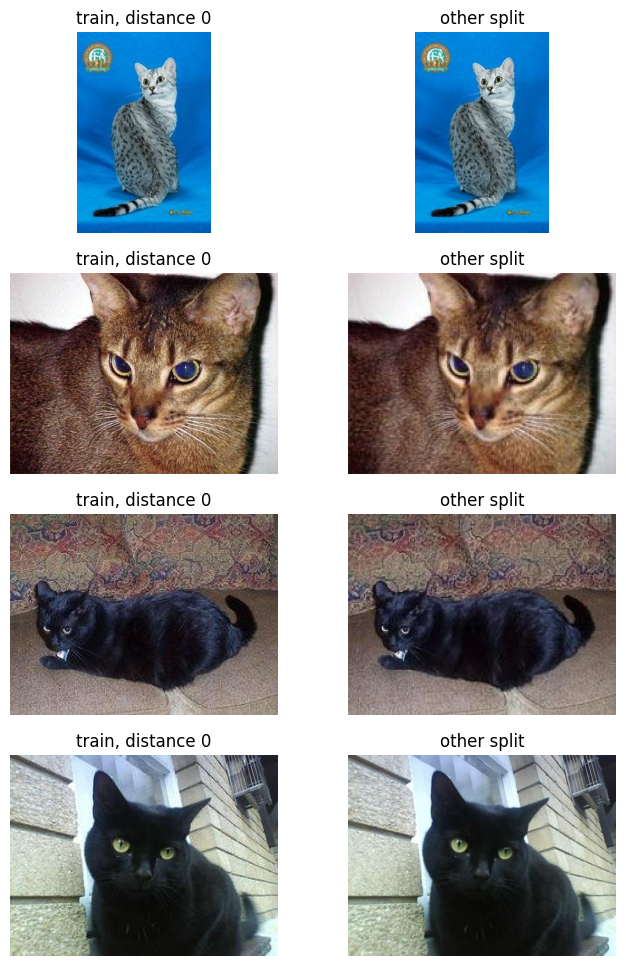

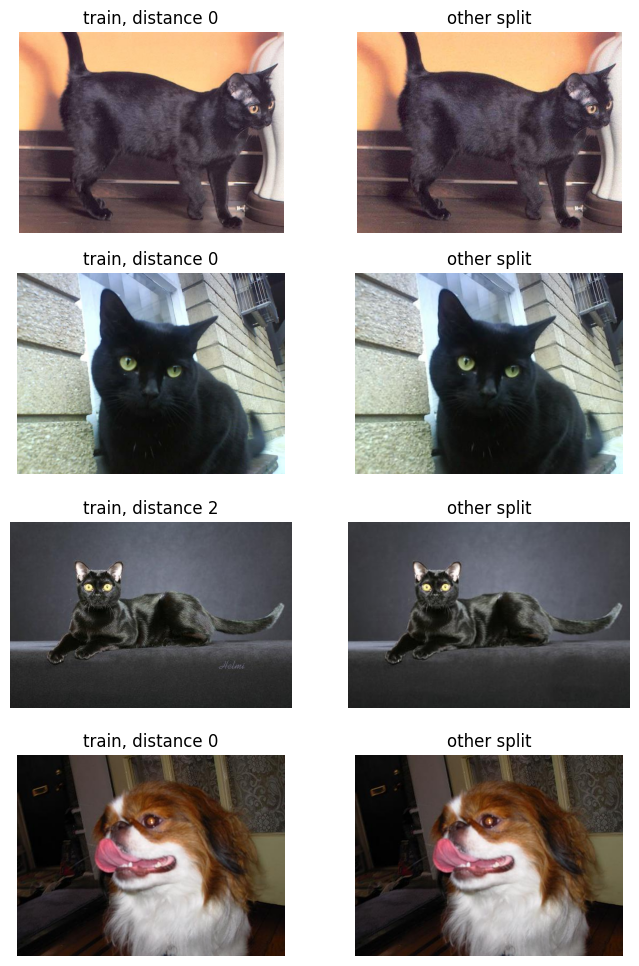

In [ ]:
tv = find_close(H["train"], H["val"])
tt = find_close(H["train"], H["test"])

def show_pairs(pairs):
    n = len(pairs)
    plt.figure(figsize=(8, 3 * n))
    for i, (pa, pb, d) in enumerate(pairs):
        plt.subplot(n, 2, 2 * i + 1)
        plt.imshow(Image.open(pa)); plt.axis("off")
        plt.title(f"train, distance {d}")
        plt.subplot(n, 2, 2 * i + 2)
        plt.imshow(Image.open(pb)); plt.axis("off")
        plt.title("other split")
    plt.show()

show_pairs(tv)
show_pairs(tt[:4])
show_pairs(tt[4:])

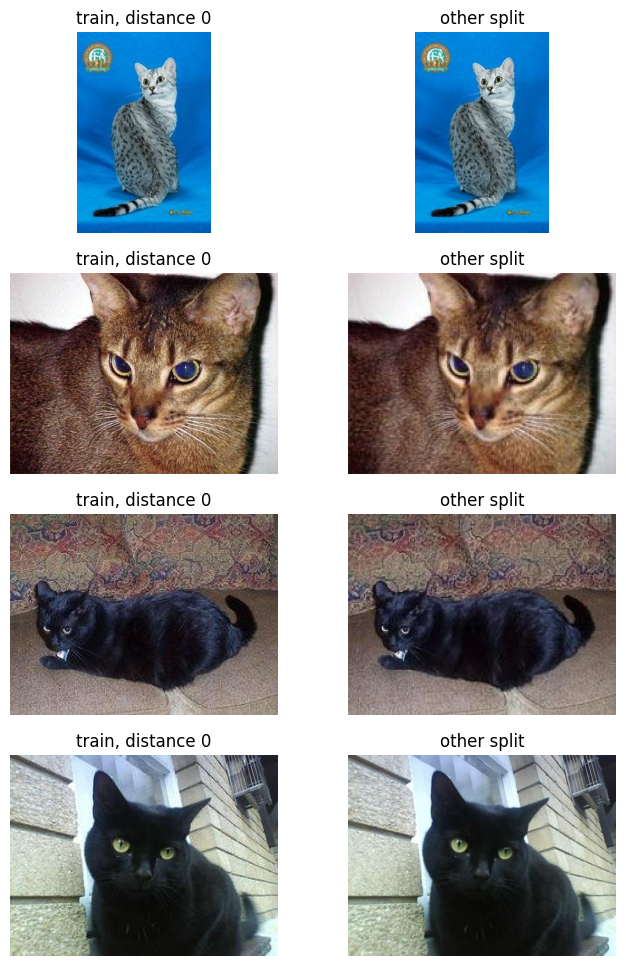

In [ ]:
show_pairs(tt[:4])

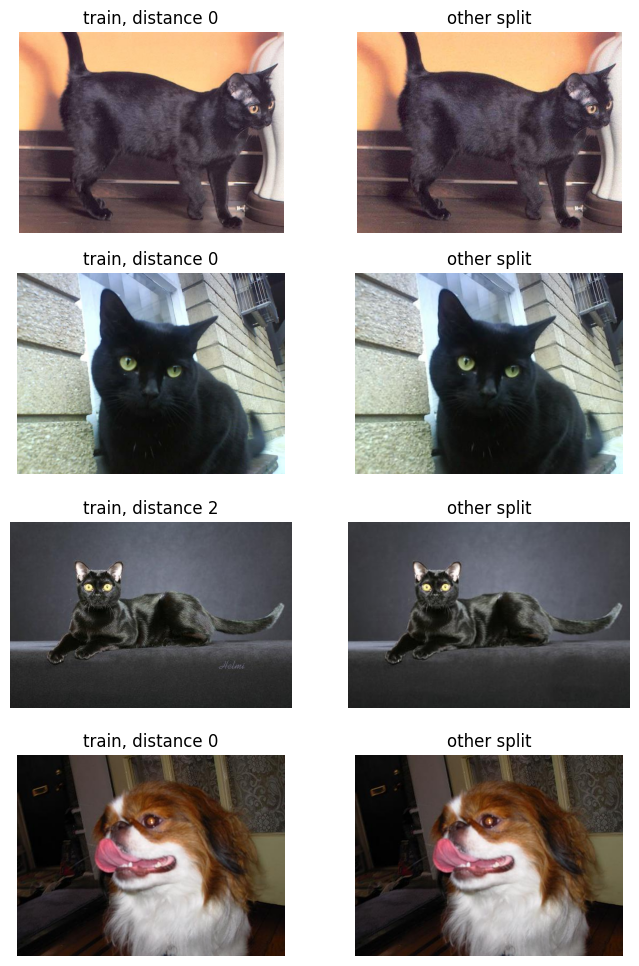

In [ ]:
show_pairs(tt[4:])

In [ ]:
for pa, pb, d in tv:
    print("VAL ", pa.split("/")[-1], "<->", pb.split("/")[-1], d)
for pa, pb, d in tt:
    print("TEST", pa.split("/")[-1], "<->", pb.split("/")[-1], d)

VAL  Bombay_136.jpg <-> Bombay_150.jpg 0
VAL  Abyssinian_56.jpg <-> Abyssinian_24.jpg 2
VAL  Abyssinian_177.jpg <-> Abyssinian_11.jpg 0
VAL  British_Shorthair_271.jpg <-> British_Shorthair_186.jpg 0
TEST Egyptian_Mau_6.jpg <-> Egyptian_Mau_186.jpg 0
TEST Abyssinian_87.jpg <-> Abyssinian_5.jpg 0
TEST Bombay_82.jpg <-> Bombay_146.jpg 0
TEST Bombay_107.jpg <-> Bombay_19.jpg 0
TEST Bombay_79.jpg <-> Bombay_97.jpg 0
TEST Bombay_132.jpg <-> Bombay_19.jpg 0
TEST Bombay_114.jpg <-> Bombay_139.jpg 2
TEST japanese_chin_188.jpg <-> japanese_chin_78.jpg 0


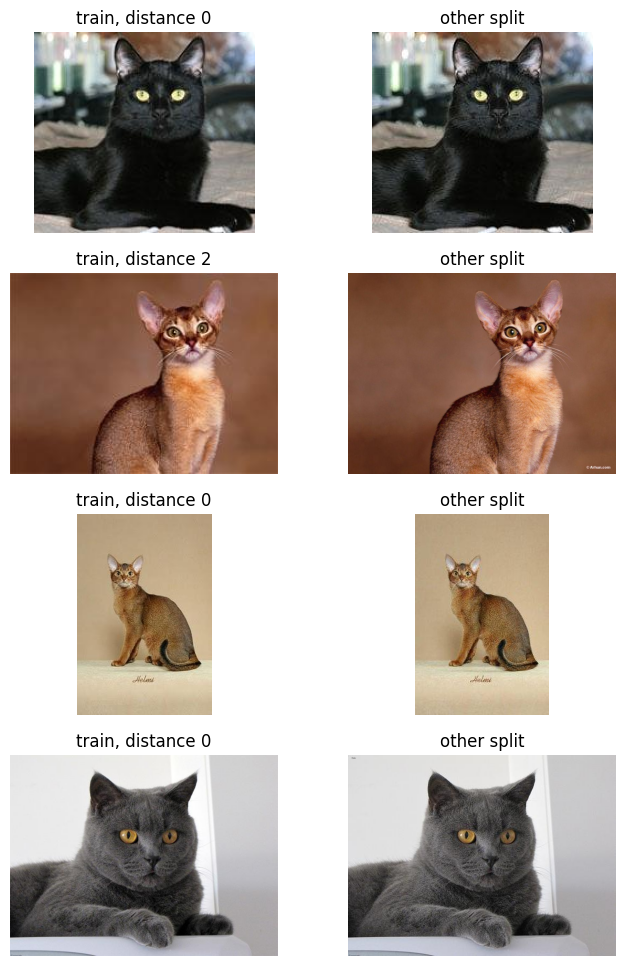

In [ ]:
show_pairs(tv)

In [ ]:
import shutil, pandas as pd
os.makedirs("removed", exist_ok=True)

to_remove = {pb for _, pb, _ in tv + tt}
print(len(to_remove), "files to remove")

for p in to_remove:
    shutil.move(p, "removed/" + p.replace("/", "_"))

pd.Series(sorted(to_remove)).to_csv("removed_duplicates.csv", index=False)

11 files to remove


In [ ]:
for s in ["train", "val", "test"]:
    for c in ["cat", "dog"]:
        print(s, c, len(os.listdir(f"dataset/{s}/{c}")))

train cat 1659
train dog 1660
val cat 352
val dog 355
test cat 350
test dog 355


In [ ]:
H = {s: [(p, h) for p, h in H[s] if os.path.exists(p)] for s in H}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(a, "vs", b, "->", len(find_close(H[a], H[b])), "close pairs")

train vs val -> 0 close pairs
train vs test -> 0 close pairs
val vs test -> 0 close pairs


In [ ]:
!zip -rq dataset_clean.zip dataset
!cp dataset_clean.zip /content/drive/MyDrive/

In [ ]:
!ls -lh /content/drive/MyDrive/dataset_clean.zip

-rw------- 1 root root 139M Oct 25 10:54 /content/drive/MyDrive/dataset_clean.zip


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

val_ds = load("val", False).prefetch(AUTOTUNE)
test_ds = load("test", False).prefetch(AUTOTUNE)

y_true = np.concatenate([y.numpy() for _, y in val_ds]).ravel()

for name, m in [("CNN v2", model2), ("Frozen", model3), ("Fine-tuned", model4)]:
    p = m.predict(val_ds, verbose=0).ravel()
    pred = (p > 0.5).astype(int)
    print("=====", name)
    print(confusion_matrix(y_true, pred))
    print(classification_report(y_true, pred,
          target_names=["cat", "dog"], digits=4))

Found 707 files belonging to 2 classes.
Found 705 files belonging to 2 classes.
===== CNN v2
[[335  17]
 [ 67 288]]
              precision    recall  f1-score   support

         cat     0.8333    0.9517    0.8886       352
         dog     0.9443    0.8113    0.8727       355

    accuracy                         0.8812       707
   macro avg     0.8888    0.8815    0.8807       707
weighted avg     0.8890    0.8812    0.8806       707

===== Frozen
[[349   3]
 [  3 352]]
              precision    recall  f1-score   support

         cat     0.9915    0.9915    0.9915       352
         dog     0.9915    0.9915    0.9915       355

    accuracy                         0.9915       707
   macro avg     0.9915    0.9915    0.9915       707
weighted avg     0.9915    0.9915    0.9915       707

===== Fine-tuned
[[344   8]
 [  1 354]]
              precision    recall  f1-score   support

         cat     0.9971    0.9773    0.9871       352
         dog     0.9779    0.9972    0.9874  

In [ ]:
ls

baseline_cnn.keras     drive/                       removed_duplicates.csv
baseline_cnn_v2.keras  mobilenetv2_finetuned.keras  sample_data/
dataset/               mobilenetv2_frozen.keras
dataset_clean.zip      removed/


In [ ]:
raw_test = load("test", False)
test_files = raw_test.file_paths
test_ds = raw_test.prefetch(AUTOTUNE)
print(len(test_files))

Found 705 files belonging to 2 classes.
705


===== CNN v2
[[323  27]
 [ 74 281]]
              precision    recall  f1-score   support

         cat     0.8136    0.9229    0.8648       350
         dog     0.9123    0.7915    0.8477       355

    accuracy                         0.8567       705
   macro avg     0.8630    0.8572    0.8562       705
weighted avg     0.8633    0.8567    0.8562       705

===== Frozen
[[349   1]
 [  2 353]]
              precision    recall  f1-score   support

         cat     0.9943    0.9971    0.9957       350
         dog     0.9972    0.9944    0.9958       355

    accuracy                         0.9957       705
   macro avg     0.9957    0.9958    0.9957       705
weighted avg     0.9957    0.9957    0.9957       705

===== Fine-tuned
[[346   4]
 [  1 354]]
              precision    recall  f1-score   support

         cat     0.9971    0.9886    0.9928       350
         dog     0.9888    0.9972    0.9930       355

    accuracy                         0.9929       705
   macro avg    

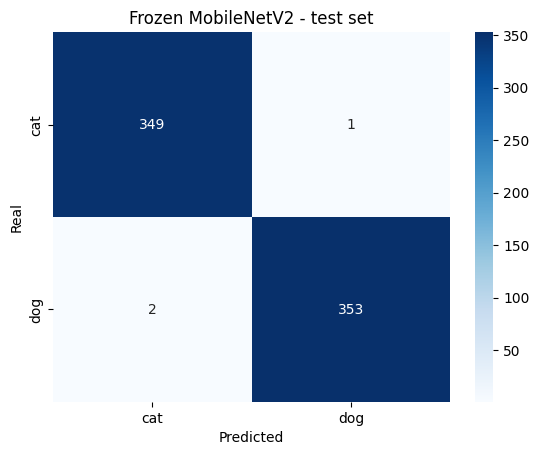

In [ ]:
import seaborn as sns

y_test = np.concatenate([y.numpy() for _, y in test_ds]).ravel()
test_probs = {}

for name, m in [("CNN v2", model2), ("Frozen", model3), ("Fine-tuned", model4)]:
    p = m.predict(test_ds, verbose=0).ravel()
    test_probs[name] = p
    pred = (p > 0.5).astype(int)
    print("=====", name)
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred,
          target_names=["cat", "dog"], digits=4))

cm = confusion_matrix(y_test, (test_probs["Frozen"] > 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["cat", "dog"], yticklabels=["cat", "dog"])
plt.xlabel("Predicted"); plt.ylabel("Real")
plt.title("Frozen MobileNetV2 - test set")
plt.savefig("confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

np.save("test_probs_frozen.npy", test_probs["Frozen"])

In [ ]:
rows = []
for s in ["train", "val", "test"]:
    for c in ["cat", "dog"]:
        for fn in sorted(os.listdir(f"dataset/{s}/{c}")):
            rows.append((s, c, fn))
pd.DataFrame(rows, columns=["split", "label", "file"]).to_csv("splits_final.csv", index=False)

!cp splits_final.csv removed_duplicates.csv /content/drive/MyDrive/

3 mistakes


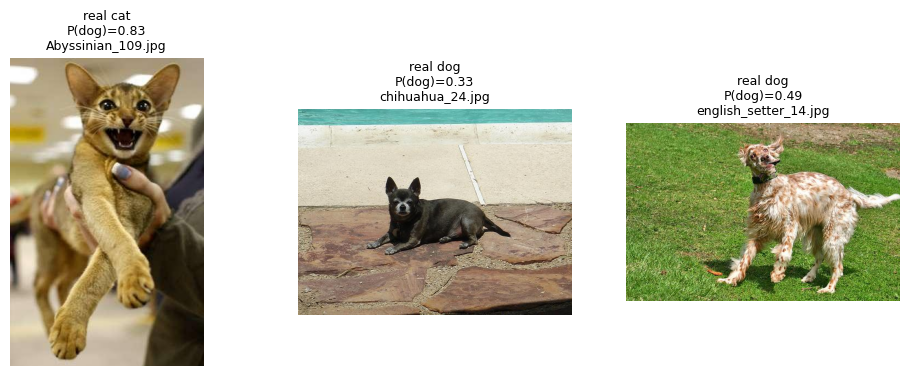

In [ ]:
p = test_probs["Frozen"]
pred = (p > 0.5).astype(int)
wrong = np.where(pred != y_test)[0]
print(len(wrong), "mistakes")

plt.figure(figsize=(12, 4))
for k, i in enumerate(wrong):
    plt.subplot(1, len(wrong), k + 1)
    plt.imshow(Image.open(test_files[i])); plt.axis("off")
    real = "cat" if y_test[i] == 0 else "dog"
    plt.title(f"real {real}\nP(dog)={p[i]:.2f}\n{os.path.basename(test_files[i])}",
              fontsize=9)
plt.show()

In [ ]:
p_val = model3.predict(val_ds, verbose=0).ravel()
p_te = test_probs["Frozen"]

def band_report(p, y, low, high):
    certain = (p <= low) | (p >= high)
    pred = (p > 0.5).astype(int)
    acc = (pred[certain] == y[certain]).mean()
    return certain.mean(), acc, (~certain).sum()

for low, high in [(0.5, 0.5), (0.4, 0.6), (0.3, 0.7), (0.2, 0.8), (0.1, 0.9)]:
    cv, av, nv = band_report(p_val, y_true, low, high)
    ct, at, nt = band_report(p_te, y_test, low, high)
    print(f"band {low}-{high} | VAL: answered {cv:.1%}, acc {av:.2%}, flagged {nv}"
          f" | TEST: answered {ct:.1%}, acc {at:.2%}, flagged {nt}")

band 0.5-0.5 | VAL: answered 100.0%, acc 99.15%, flagged 0 | TEST: answered 100.0%, acc 99.57%, flagged 0
band 0.4-0.6 | VAL: answered 99.7%, acc 99.29%, flagged 2 | TEST: answered 99.9%, acc 99.72%, flagged 1
band 0.3-0.7 | VAL: answered 99.3%, acc 99.29%, flagged 5 | TEST: answered 99.6%, acc 99.86%, flagged 3
band 0.2-0.8 | VAL: answered 98.7%, acc 99.28%, flagged 9 | TEST: answered 99.1%, acc 99.86%, flagged 6
band 0.1-0.9 | VAL: answered 96.6%, acc 99.56%, flagged 24 | TEST: answered 98.3%, acc 100.00%, flagged 12


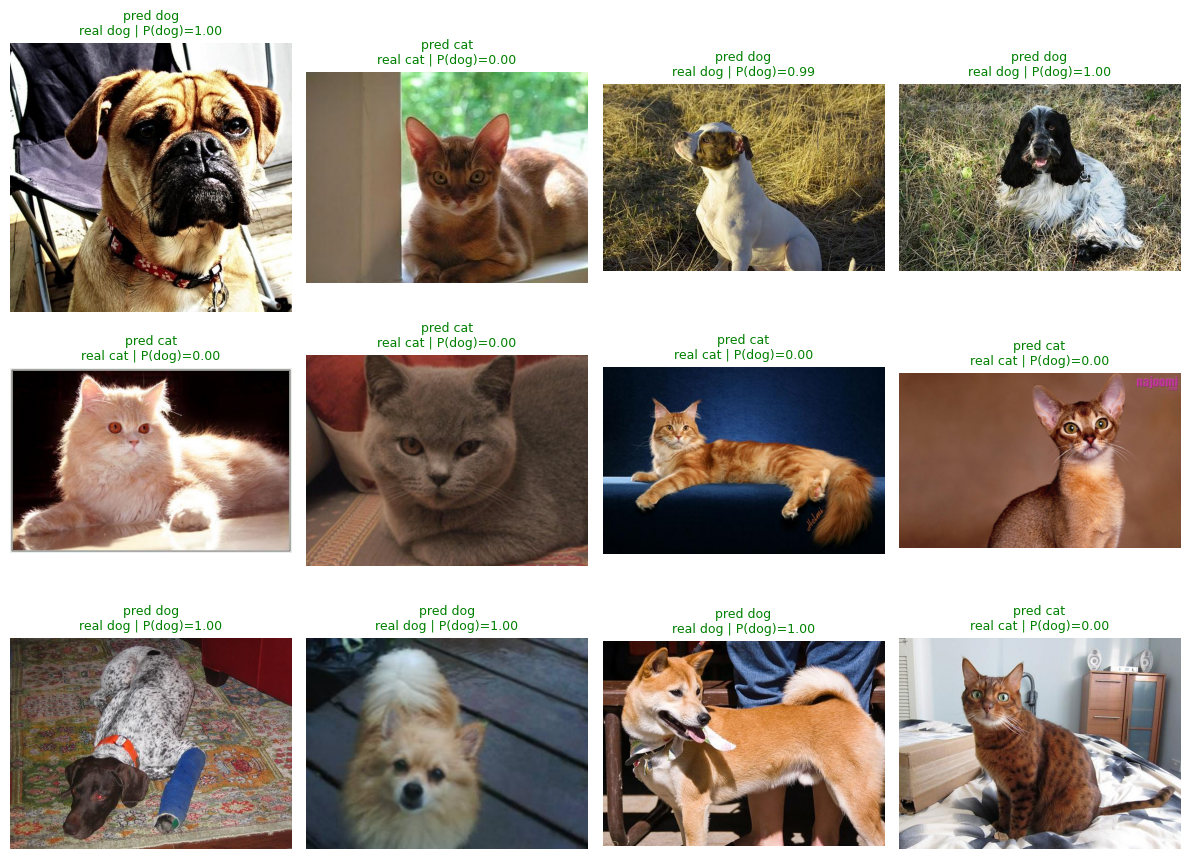

In [ ]:
rng = np.random.default_rng(0)
idx = rng.choice(len(test_files), 12, replace=False)

plt.figure(figsize=(12, 9))
for k, i in enumerate(idx):
    plt.subplot(3, 4, k + 1)
    plt.imshow(Image.open(test_files[i])); plt.axis("off")
    prob = p_te[i]
    label = "dog" if prob > 0.5 else "cat"
    real = "dog" if y_test[i] == 1 else "cat"
    flag = " (uncertain)" if 0.1 < prob < 0.9 else ""
    plt.title(f"pred {label}{flag}\nreal {real} | P(dog)={prob:.2f}",
              fontsize=9, color="green" if label == real else "red")
plt.tight_layout()
plt.savefig("example_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
base3 = model3.layers[-4]     # MobileNetV2
gap = model3.layers[-3]       # global average pooling
dense = model3.layers[-1]     # final layer
print(base3.name, gap.name, dense.name)

last_conv = tf.keras.Model(base3.input, base3.get_layer("out_relu").output)

def gradcam(img):
    x = tf.keras.applications.mobilenet_v2.preprocess_input(tf.expand_dims(img, 0))
    with tf.GradientTape() as tape:
        conv_out = last_conv(x)
        prob = dense(gap(conv_out))
        score = prob[0, 0] if prob[0, 0] > 0.5 else 1 - prob[0, 0]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), float(prob[0, 0])

def show_cam(paths):
    n = len(paths)
    plt.figure(figsize=(3 * n, 6))
    for k, p in enumerate(paths):
        img = np.array(Image.open(p).convert("RGB").resize((224, 224)), dtype="float32")
        cam, prob = gradcam(img)
        cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0]
        plt.subplot(2, n, k + 1)
        plt.imshow(img.astype("uint8")); plt.axis("off")
        plt.title(f"{os.path.basename(p)}\nP(dog)={prob:.2f}", fontsize=8)
        plt.subplot(2, n, n + k + 1)
        plt.imshow(img.astype("uint8")); plt.imshow(cam, cmap="jet", alpha=0.45)
        plt.axis("off")
        plt.savefig("gradcam_" + os.path.basename(paths[0]).split(".")[0] + ".png",
            dpi=150, bbox_inches="tight")
    plt.show()

paths = [test_files[i] for i in list(wrong) + list(idx[:5])]
show_cam(paths[:4])
show_cam(paths[4:])

NameError: name 'model3' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q /content/drive/MyDrive/dataset_clean.zip
!cp /content/drive/MyDrive/mobilenetv2_frozen.keras .

import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report

AUTOTUNE = tf.data.AUTOTUNE

def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"dataset/{split}", image_size=(224, 224),
        batch_size=32, label_mode="binary",
        shuffle=shuffle, seed=42)

model3 = tf.keras.models.load_model("mobilenetv2_frozen.keras")

raw_test = load("test", False)
test_files = raw_test.file_paths
test_ds = raw_test.prefetch(AUTOTUNE)
y_test = np.concatenate([y.numpy() for _, y in test_ds]).ravel()
p_te = model3.predict(test_ds, verbose=0).ravel()

wrong = np.where((p_te > 0.5).astype(int) != y_test)[0]
rng = np.random.default_rng(0)
idx = rng.choice(len(test_files), 12, replace=False)

print(len(test_files), "test photos,", len(wrong), "mistakes")
for i in wrong:
    print(os.path.basename(test_files[i]), round(float(p_te[i]), 2))

Mounted at /content/drive
Found 705 files belonging to 2 classes.
705 test photos, 3 mistakes
Abyssinian_109.jpg 0.83
chihuahua_24.jpg 0.33
english_setter_14.jpg 0.49


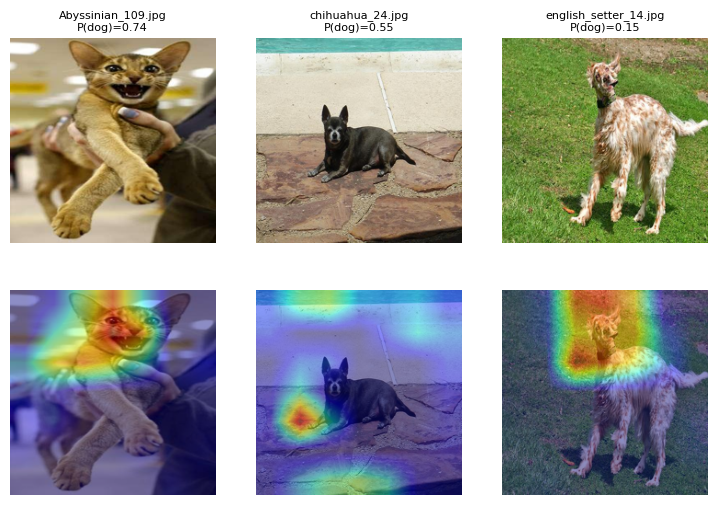

In [ ]:
base3 = model3.layers[-4]
gap = model3.layers[-3]
dense = model3.layers[-1]
last_conv = tf.keras.Model(base3.input, base3.get_layer("out_relu").output)

def gradcam(img):
    x = tf.keras.applications.mobilenet_v2.preprocess_input(tf.expand_dims(img, 0))
    with tf.GradientTape() as tape:
        conv_out = last_conv(x)
        prob = dense(gap(conv_out))
        score = prob[0, 0] if prob[0, 0] > 0.5 else 1 - prob[0, 0]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), float(prob[0, 0])

def show_cam(paths):
    n = len(paths)
    plt.figure(figsize=(3 * n, 6))
    for k, p in enumerate(paths):
        img = np.array(Image.open(p).convert("RGB").resize((224, 224)), dtype="float32")
        cam, prob = gradcam(img)
        cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0]
        plt.subplot(2, n, k + 1)
        plt.imshow(img.astype("uint8")); plt.axis("off")
        plt.title(f"{os.path.basename(p)}\nP(dog)={prob:.2f}", fontsize=8)
        plt.subplot(2, n, n + k + 1)
        plt.imshow(img.astype("uint8")); plt.imshow(cam, cmap="jet", alpha=0.45)
        plt.axis("off")
    plt.savefig("gradcam_" + os.path.basename(paths[0]).split(".")[0] + ".png",
                dpi=150, bbox_inches="tight")
    plt.show()

mistakes = [test_files[i] for i in wrong]
show_cam(mistakes)

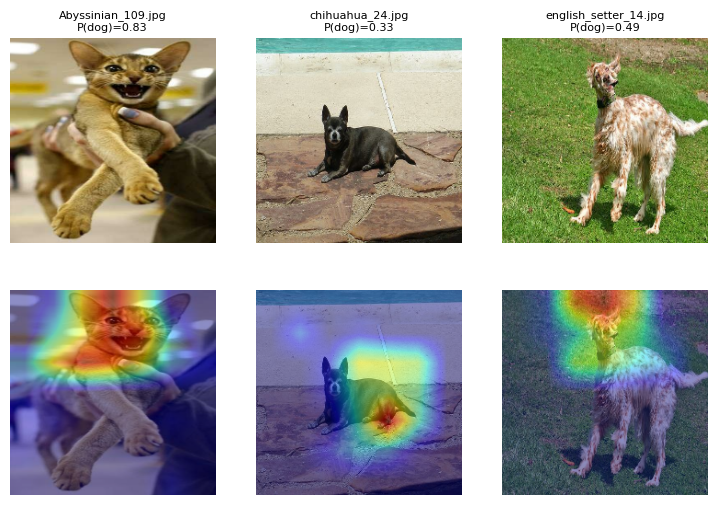

In [ ]:
def read_img(path):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    return tf.image.resize(img, (224, 224), method="bilinear").numpy()

def show_cam(paths):
    n = len(paths)
    plt.figure(figsize=(3 * n, 6))
    for k, p in enumerate(paths):
        img = read_img(p)
        cam, prob = gradcam(img)
        cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0]
        plt.subplot(2, n, k + 1)
        plt.imshow(img.astype("uint8")); plt.axis("off")
        plt.title(f"{os.path.basename(p)}\nP(dog)={prob:.2f}", fontsize=8)
        plt.subplot(2, n, n + k + 1)
        plt.imshow(img.astype("uint8")); plt.imshow(cam, cmap="jet", alpha=0.45)
        plt.axis("off")
    plt.savefig("gradcam_" + os.path.basename(paths[0]).split(".")[0] + ".png",
                dpi=150, bbox_inches="tight")
    plt.show()

show_cam(mistakes)

In [ ]:
from scipy.ndimage import gaussian_filter

imgs = np.stack([read_img(p) for p in test_files]).astype("float32")
print(imgs.shape)

def darken(x): return x * 0.35
def brighten(x): return np.clip(x * 1.8, 0, 255)
def low_contrast(x):
    m = x.mean(axis=(1, 2, 3), keepdims=True)
    return m + (x - m) * 0.4
def noise(x):
    r = np.random.default_rng(0)
    return np.clip(x + r.normal(0, 40, x.shape), 0, 255)
def blur(x): return gaussian_filter(x, sigma=(0, 3, 3, 0))
def low_res(x):
    small = tf.image.resize(x, (32, 32))
    return tf.image.resize(small, (224, 224)).numpy()
def grayscale(x): return np.repeat(x.mean(-1, keepdims=True), 3, axis=-1)
def occlude(x):
    x = x.copy()
    r = np.random.default_rng(0)
    for i in range(len(x)):
        a, b = r.integers(0, 224 - 90, 2)
        x[i, a:a + 90, b:b + 90, :] = 0
    return x

tests = {"original": lambda x: x, "darker": darken, "brighter": brighten,
         "low contrast": low_contrast, "noise": noise, "blur": blur,
         "low resolution": low_res, "grayscale": grayscale, "occluded": occlude}

rows = []
for name, f in tests.items():
    p = model3.predict(f(imgs), batch_size=32, verbose=0).ravel()
    pred = (p > 0.5).astype(int)
    rows.append((name, (pred == y_test).mean(),
                 (pred[y_test == 0] == 0).mean(), (pred[y_test == 1] == 1).mean()))

res = pd.DataFrame(rows, columns=["test", "accuracy", "cat recall", "dog recall"])
print(res.round(4))
res.to_csv("robustness_synthetic.csv", index=False)

(705, 224, 224, 3)
             test  accuracy  cat recall  dog recall
0        original    0.9957      0.9971      0.9944
1          darker    0.9872      1.0000      0.9746
2        brighter    0.9872      0.9771      0.9972
3    low contrast    0.9816      1.0000      0.9634
4           noise    0.7830      0.6657      0.8986
5            blur    0.8652      0.8457      0.8845
6  low resolution    0.6879      0.4057      0.9662
7       grayscale    0.9929      0.9914      0.9944
8        occluded    0.9418      0.9714      0.9127
